In [6]:
# ── CONFIG ────────────────────────────────────────────────────────────────
DEV_MODE = True
# ─────────────────────────────────────────────────────────────────────────
import os
import warnings
warnings.filterwarnings("ignore")

if DEV_MODE:
    import importlib
    import db as _db; importlib.reload(_db)
    import fundamentals as _f; importlib.reload(_f)
    from quality_scores import line_items as _li; importlib.reload(_li)
    from quality_scores import piotroski as _pi; importlib.reload(_pi)
    from quality_scores import piotroski_plots as _pp; importlib.reload(_pp)

from db import get_engine
eng = get_engine()
from quality_scores.piotroski import piotroski_f_score, print_report

print(f"✅ Modules {'reloaded' if DEV_MODE else 'imported'} | DEV_MODE={'ON' if DEV_MODE else 'OFF'}")

✅ Modules reloaded | DEV_MODE=ON


# PIOTROSKI F-SCORE
## ΤΙ ΕΙΝΑΙ:
9 ερωτήσεις "ναι/όχι" για την οικονομική υγεία μιας εταιρείας,
συγκρίνοντας την τελευταία χρονιά (φέτος) με την προηγούμενη (πέρσι).
Κάθε "ναι" = 1 πόντος. Γενικά: 7–9 = υγιής, 0–3 = αδύναμη.
Αν λείπει κάποιο νούμερο, η ερώτηση ΔΕΝ μετράει ως αποτυχία — γράφεται
"δεν αξιολογήθηκε" και το score δίνεται ως "πόντοι / όσα ελέγχθηκαν".

## - ΚΕΡΔΟΦΟΡΙΑ -

## 1. Κερδοφόρα (ROA > 0)
    Έβγαλε κέρδος φέτος;  ROA = κέρδη / assets στην ΑΡΧΗ της χρονιάς.
    Παράδειγμα: κέρδη 10, assets αρχής 100 → ROA 10% → ΝΑΙ.

## 2. Θετικές ταμειακές ροές (CFO > 0)
    Μπήκαν πραγματικά χρήματα στο ταμείο από τη λειτουργία της εταιρείας;
    τα κέρδη μπορεί να είναι "στα χαρτιά" — το ταμείο δεν ξεγελιέται εύκολα.

## 3. ROA βελτιώθηκε
    Η κερδοφορία ανά ευρώ assets ανέβηκε σε σχέση με πέρσι;
    Παράδειγμα: πέρσι 9%, φέτος 11% → ΝΑΙ.
    Γιατί assets ΑΡΧΗΣ χρονιάς: αν η εταιρεία αγόρασε άλλη τον Δεκέμβριο
    και τα assets διπλασιάστηκαν, αυτά δεν δούλεψαν όλη τη χρονιά. Με τα
    assets του τέλους θα φαινόταν ψευδώς ότι η κερδοφορία έπεσε στο μισό.

## 4. Ταμείο > λογιστικά κέρδη
    Οι ταμειακές ροές είναι μεγαλύτερες από τα κέρδη;
    Παράδειγμα: κέρδη 10, ταμείο 14 → ΝΑΙ (τα κέρδη "στηρίζονται" σε
    μετρητά). Αν ήταν κέρδη 10, ταμείο 3 → ΟΧΙ: μεγάλο μέρος των κερδών
    είναι απαιτήσεις/λογιστικές εγγραφές, κλασικό προειδοποιητικό σημάδι.

## - ΧΡΕΟΣ & ΡΕΥΣΤΟΤΗΤΑ - 

## 5. Λιγότερο χρέος
    Μακροπρόθεσμο χρέος / ΜΕΣΟ ΟΡΟ assets έπεσε σε σχέση με πέρσι;
    Παράδειγμα: πέρσι 25%, φέτος 20% → ΝΑΙ.
    Συγκρίνεται πάντα το ΙΔΙΟ μέτρο και τις δύο χρονιές: αν πέρσι
    δηλώθηκαν δύο κομμάτια χρέους (30 + 70) και φέτος μόνο το ένα (70),
    συγκρίνουμε 70 με 70 — όχι 100 με 70, που θα έδειχνε ψεύτικη μείωση.

## 6. Καλύτερη ρευστότητα (current ratio)
    Current ratio = ό,τι γίνεται μετρητά μέσα σε 1 χρόνο / ό,τι πρέπει
    να πληρωθεί μέσα σε 1 χρόνο. Ανέβηκε σε σχέση με πέρσι;
    Παράδειγμα: πέρσι 1.40x, φέτος 1.25x → ΟΧΙ.

## 7. Όχι νέες μετοχές
    Ο αριθμός μετοχών έμεινε ίδιος ή μειώθηκε; Νέες μετοχές = η πίτα
    μοιράζεται σε περισσότερους (dilution). Buybacks = ΝΑΙ.
    Αν ο αριθμός άλλαξε κατά ~x2, x4, x10 κτλ. είναι πιθανότατα split
    (π.χ. AAPL 4:1 το 2020: 4.4B → 17B μετοχές) → "δεν αξιολογήθηκε",
    γιατί το split δεν είναι dilution.

## - ΑΠΟΔΟΤΙΚΟΤΗΤΑ - 

## 8. Μεικτό περιθώριο ↑
    Από κάθε 100€ πωλήσεων, πόσα μένουν μετά το κόστος του προϊόντος;
    Παράδειγμα: πέρσι 37.8€, φέτος 38.2€ → ΝΑΙ (καλύτερη τιμολόγηση ή
    φθηνότερη παραγωγή).

## 9. Αποδοτικότητα assets ↑ (asset turnover)
    Πόσες πωλήσεις βγάζει κάθε 1€ assets (αρχής χρονιάς);
    Παράδειγμα: πέρσι 0.71€, φέτος 0.81€ → ΝΑΙ (τα ίδια assets "δουλεύουν" περισσότερο).


── Piotroski F-Score: ULTA ──────────────────
   FY2026 vs FY2025  (filed 2026-03-26)
   Score: 6 / 8

   Κερδοφορία
   [PASS]  Κερδοφόρα (ROA > 0)          φέτος 19.2%
   [PASS]  Θετικές ταμειακές ροές       φέτος $1.50B
   [FAIL]  ROA βελτιώθηκε               πέρσι 21.0%  φέτος 19.2%
   [PASS]  Ταμείο > λογιστικά κέρδη     κέρδη $1.15B  ταμείο $1.50B

   Χρέος & ρευστότητα
   [N/A ]  Λιγότερο χρέος               πέρσι —  φέτος —
            ↳ δεν υπάρχει ίδιο μέτρο χρέους και στις δύο χρονιές
   [FAIL]  Καλύτερη ρευστότητα          πέρσι 1.70x  φέτος 1.41x
   [PASS]  Όχι νέες μετοχές             πέρσι 46.0M  φέτος 44.2M
            ↳ μετοχές στο τέλος της χρονιάς

   Αποδοτικότητα
   [PASS]  Μεικτό περιθώριο ↑           πέρσι 38.8%  φέτος 39.1%
            ↳ δηλωμένο μεικτό κέρδος
   [PASS]  Αποδοτικότητα assets ↑       πέρσι 1.98x  φέτος 2.06x


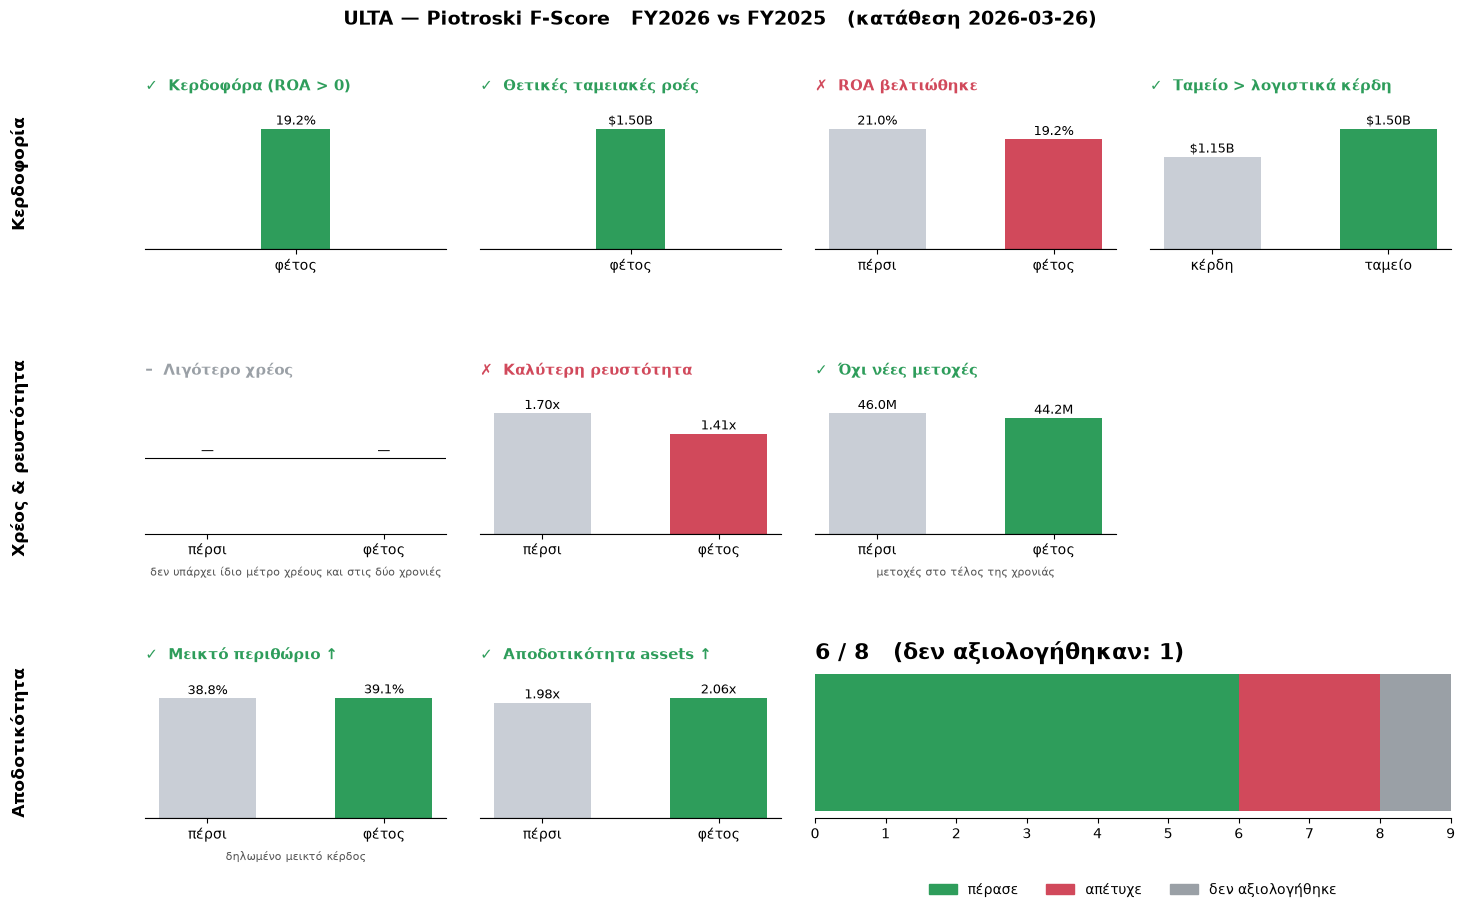

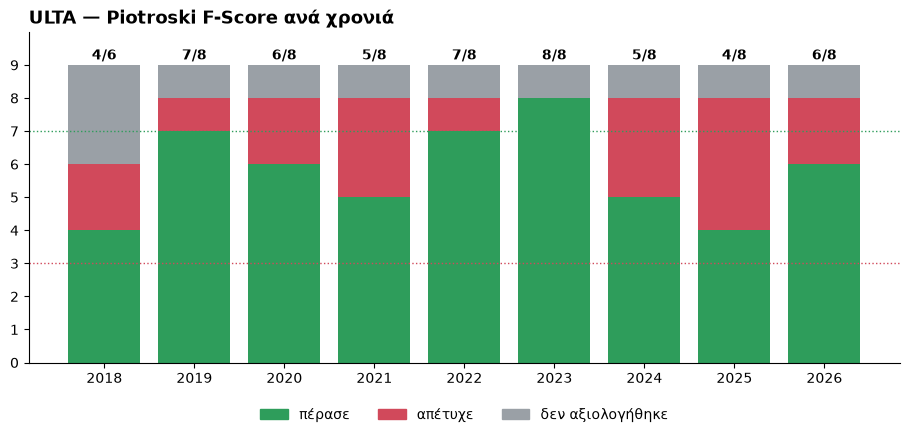

In [9]:
import matplotlib.pyplot as plt
from quality_scores.piotroski import piotroski_f_score, print_report, piotroski_history
from quality_scores.piotroski_plots import plot_report, plot_history
 
TICKER = "ULTA"
AS_OF = None  # π.χ. "2022-06-30" για "ό,τι ήξερε η αγορά τότε"
 
res = piotroski_f_score(TICKER, eng, as_of=AS_OF)
print_report(res)
plot_report(res)
plt.show()
 
plot_history(piotroski_history(TICKER, eng, n_years=10), TICKER)
plt.show()